# Practical Assignment 5: Ensemble Learning and Performance Evaluation



## 1. Import required libraries

In [4]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    AdaBoostClassifier,
    VotingClassifier,
    StackingClassifier
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

## 2. Load the dataset

In [6]:
# Keep riceClassification.csv in the same folder as this notebook.
df = pd.read_csv("riceClassification.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (18185, 12)


,id,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,EquivDiameter,Extent,Perimeter,Roundness,AspectRation,Class
0,1,4537,92.229316,64.012769,0.719916,4677,76.004525,0.657536,273.085,0.764510,1.440796,1
1,2,2872,74.691881,51.400454,0.725553,3015,60.471018,0.713009,208.317,0.831658,1.453137,1
2,3,3048,76.293164,52.043491,0.731211,3132,62.296341,0.759153,210.012,0.868434,1.465950,1
3,4,3073,77.033628,51.928487,0.738639,3157,62.551300,0.783529,210.657,0.870203,1.483456,1
4,5,3693,85.124785,56.374021,0.749282,3802,68.571668,0.769375,230.332,0.874743,1.510000,1


## 3. Understand the dataset

In [8]:
print("Column names:")
print(df.columns.tolist())

print("\\nData types:")
display(df.dtypes.to_frame("Data Type"))

print("\\nDataset information:")
df.info()

print("\\nStatistical summary:")
display(df.describe().T)

Column names:
['id', 'Area', 'MajorAxisLength', 'MinorAxisLength', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Perimeter', 'Roundness', 'AspectRation', 'Class']
\nData types:


,Data Type
id,int64
Area,int64
MajorAxisLength,float64
MinorAxisLength,float64
Eccentricity,float64
ConvexArea,int64
EquivDiameter,float64
Extent,float64
Perimeter,float64
Roundness,float64


\nDataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18185 entries, 0 to 18184
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id               18185 non-null  int64  
 1   Area             18185 non-null  int64  
 2   MajorAxisLength  18185 non-null  float64
 3   MinorAxisLength  18185 non-null  float64
 4   Eccentricity     18185 non-null  float64
 5   ConvexArea       18185 non-null  int64  
 6   EquivDiameter    18185 non-null  float64
 7   Extent           18185 non-null  float64
 8   Perimeter        18185 non-null  float64
 9   Roundness        18185 non-null  float64
 10  AspectRation     18185 non-null  float64
 11  Class            18185 non-null  int64  
dtypes: float64(8), int64(4)
memory usage: 1.7 MB
\nStatistical summary:


,count,mean,std,min,25%,50%,75%,max
id,18185.0,9093.000000,5249.701658,1.000000,4547.000000,9093.000000,13639.000000,18185.000000
Area,18185.0,7036.492989,1467.197150,2522.000000,5962.000000,6660.000000,8423.000000,10210.000000
MajorAxisLength,18185.0,151.680754,12.376402,74.133114,145.675910,153.883750,160.056214,183.211434
MinorAxisLength,18185.0,59.807851,10.061653,34.409894,51.393151,55.724288,70.156593,82.550762
Eccentricity,18185.0,0.915406,0.030575,0.676647,0.891617,0.923259,0.941372,0.966774
ConvexArea,18185.0,7225.817872,1502.006571,2579.000000,6125.000000,6843.000000,8645.000000,11008.000000
EquivDiameter,18185.0,94.132952,9.906250,56.666658,87.126656,92.085696,103.559146,114.016559
Extent,18185.0,0.616653,0.104389,0.383239,0.538530,0.601194,0.695664,0.886573
Perimeter,18185.0,351.606949,29.500620,197.015000,333.990000,353.088000,373.003000,508.511000
Roundness,18185.0,0.707998,0.067310,0.174590,0.650962,0.701941,0.769280,0.904748


## 4. Check missing values and duplicate records

In [10]:
print("Missing values in each column:")
display(df.isnull().sum().to_frame("Missing Values"))

print("Duplicate rows:", df.duplicated().sum())
print("Unique ID values:", df["id"].nunique())
print("Total records:", len(df))

# Check whether the target has the expected two classes.
print("\\nTarget class counts:")
display(df["Class"].value_counts().sort_index().to_frame("Count"))

Missing values in each column:


,Missing Values
id,0
Area,0
MajorAxisLength,0
MinorAxisLength,0
Eccentricity,0
ConvexArea,0
EquivDiameter,0
Extent,0
Perimeter,0
Roundness,0


Duplicate rows: 0
Unique ID values: 18185
Total records: 18185
\nTarget class counts:


,Count
Class,
0,8200
1,9985


## 5. Clean the dataset

In [12]:
# Convert blank text values to missing values, if any are present.
df = df.replace(r"^\\s*$", np.nan, regex=True)

# Remove duplicate records, if any are present.
df = df.drop_duplicates().copy()

print("Dataset shape after cleaning:", df.shape)
print("Missing values after cleaning:")
display(df.isnull().sum().to_frame("Missing Values"))

Dataset shape after cleaning: (18185, 12)
Missing values after cleaning:


,Missing Values
id,0
Area,0
MajorAxisLength,0
MinorAxisLength,0
Eccentricity,0
ConvexArea,0
EquivDiameter,0
Extent,0
Perimeter,0
Roundness,0


**Data observation:** The supplied `riceClassification.csv` file contains 18,185 rows and 12 columns. It has 10 numerical input features, one `id` column and one target column named `Class`. The original file has no missing values and no duplicate rows. The `id` column is an identifier, so it is excluded from model training. The imputer in the preprocessing pipeline is retained as a standard safeguard.

## 6. Exploratory Data Analysis (EDA)

### 6.1 Distribution of target classes

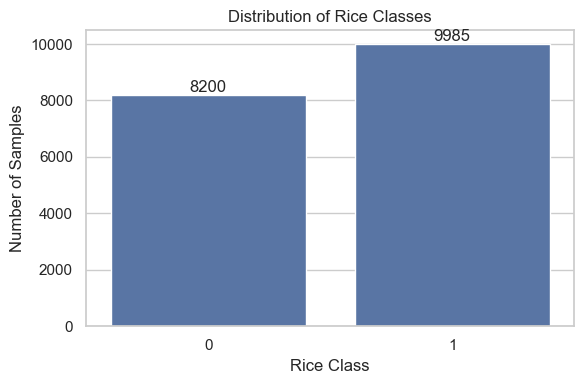

,Number of Samples
Class,
0,8200
1,9985


,Percentage
Class,
0,45.09
1,54.91


In [16]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x="Class")
plt.title("Distribution of Rice Classes")
plt.xlabel("Rice Class")
plt.ylabel("Number of Samples")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

display(df["Class"].value_counts().sort_index().to_frame("Number of Samples"))
display(
    (df["Class"].value_counts(normalize=True).sort_index() * 100)
    .round(2).to_frame("Percentage")
)

### 6.2 Distribution of numerical input features

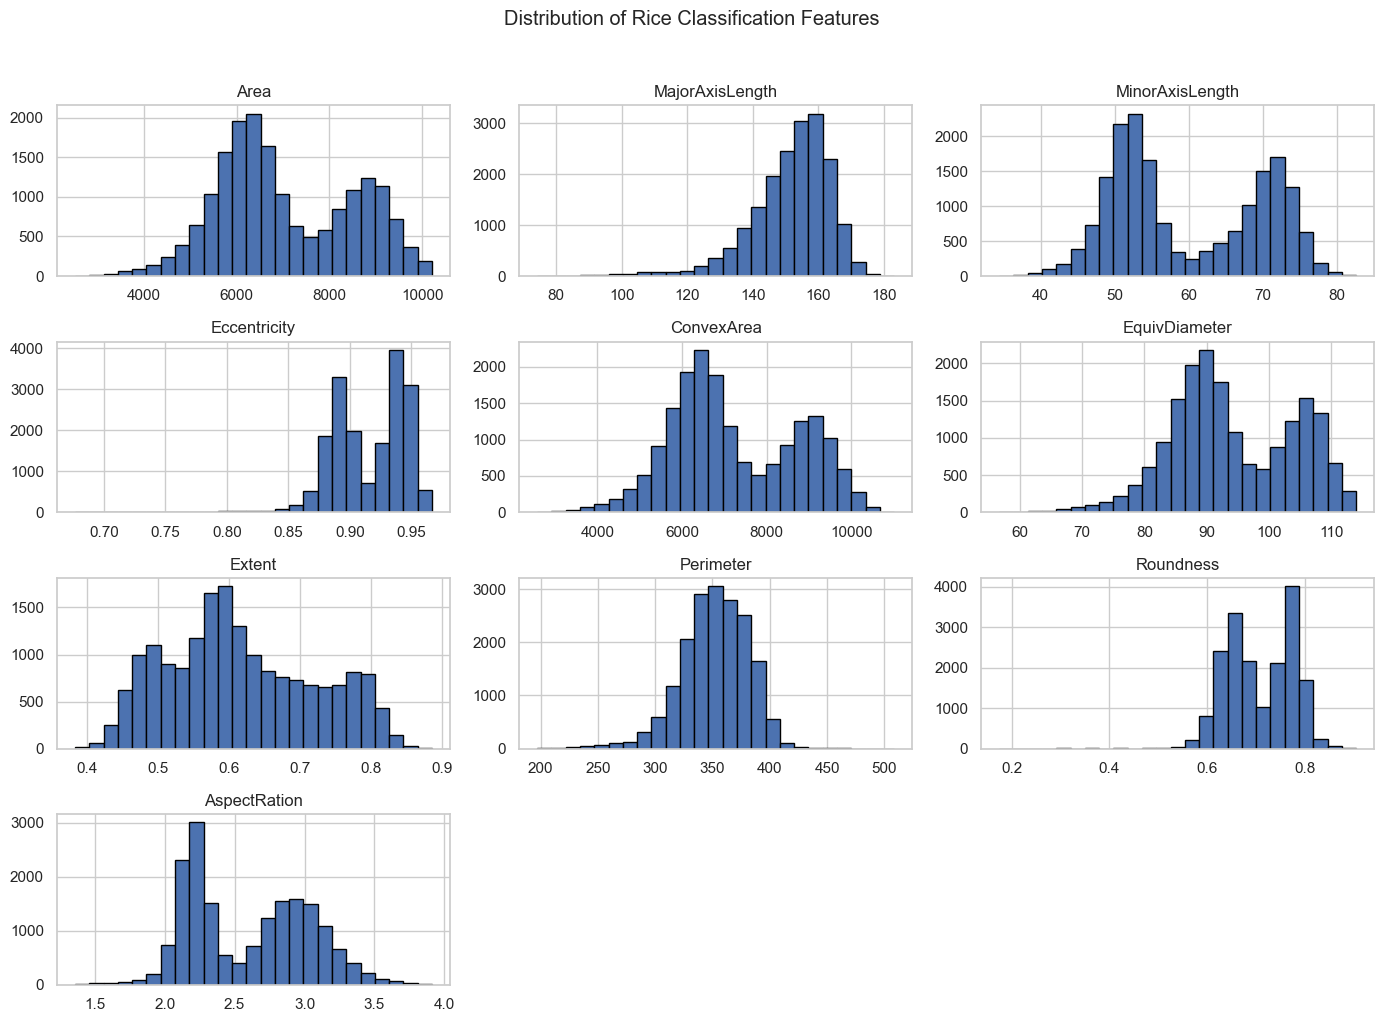

In [18]:
feature_columns = [
    col for col in df.select_dtypes(include=np.number).columns
    if col not in ["id", "Class"]
]

df[feature_columns].hist(
    figsize=(14, 10),
    bins=25,
    edgecolor="black"
)
plt.suptitle("Distribution of Rice Classification Features", y=1.02)
plt.tight_layout()
plt.show()

### 6.3 Boxplots for feature spread and potential outliers

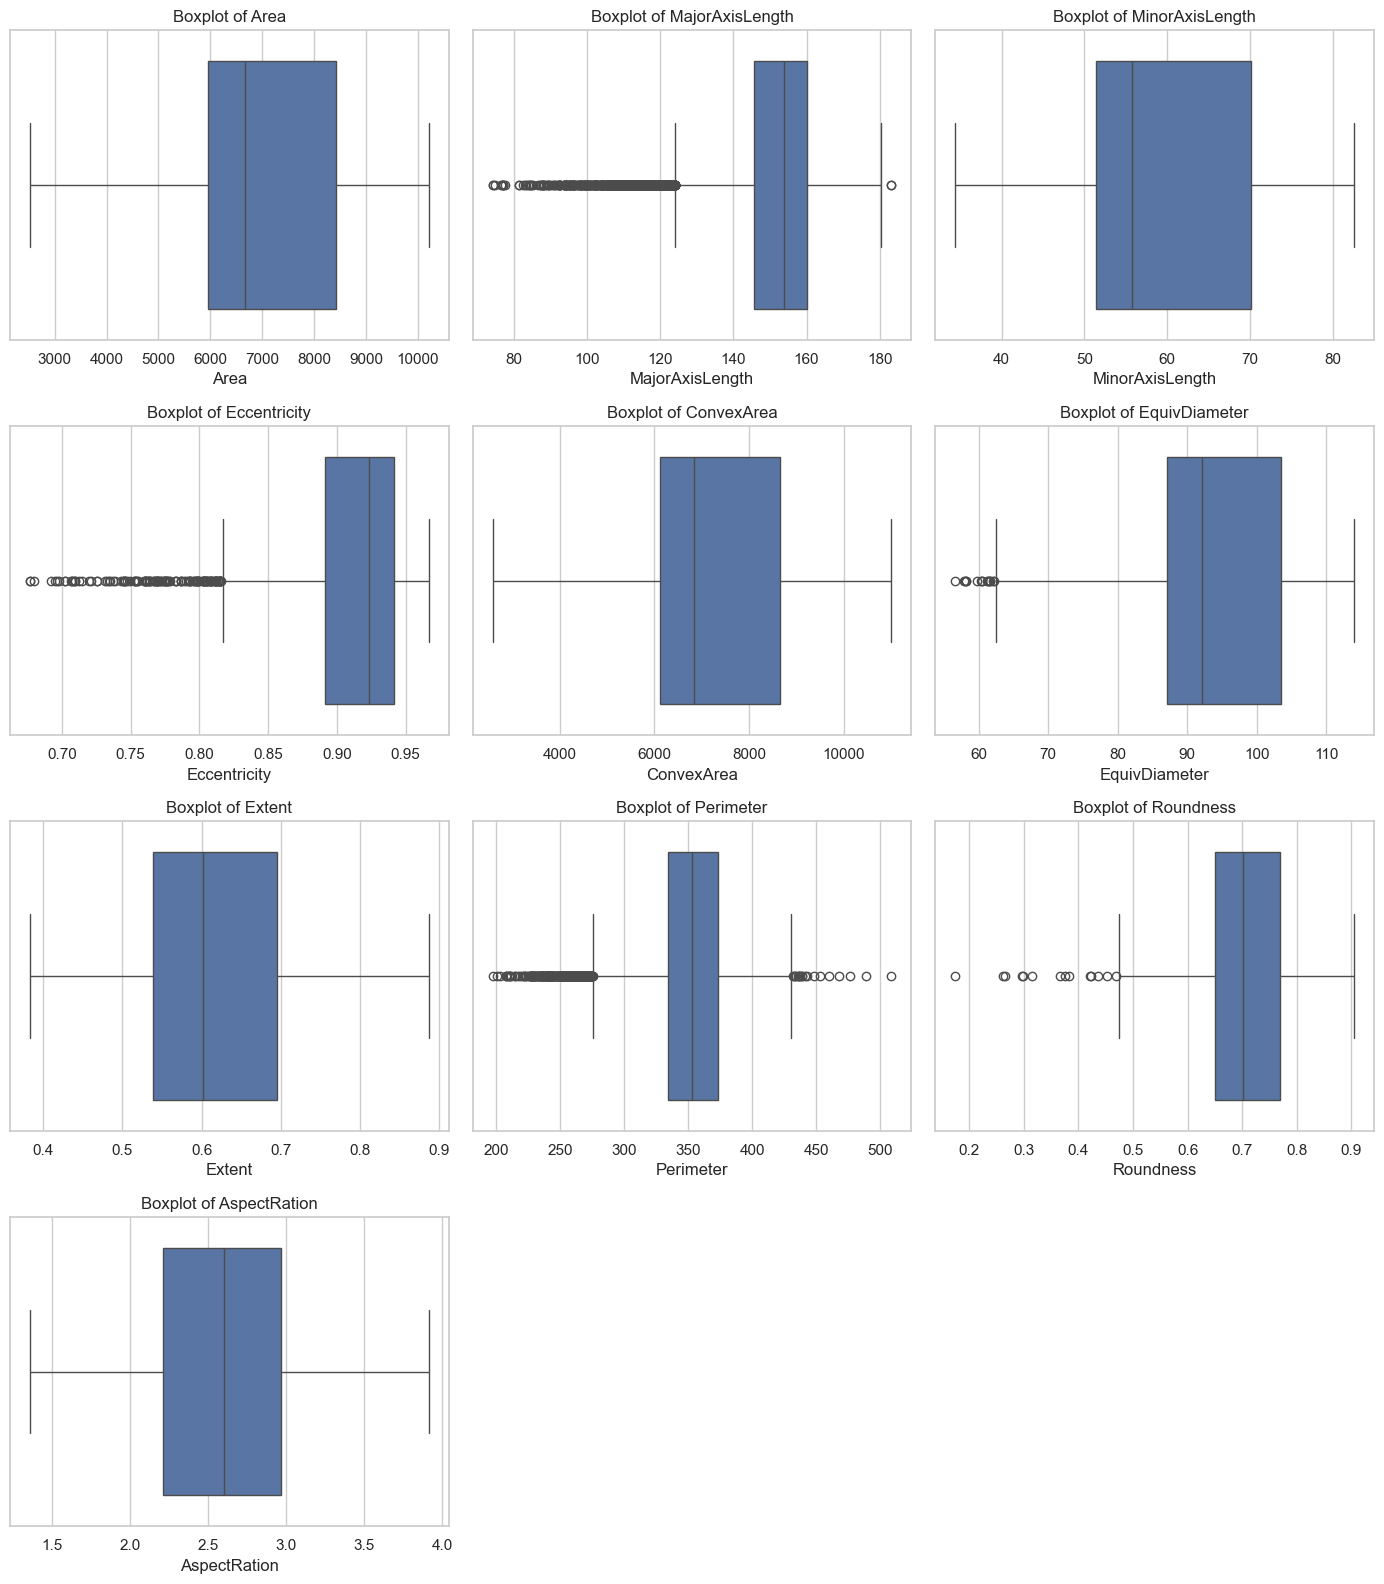

In [20]:
n_features = len(feature_columns)
n_cols = 3
n_rows = int(np.ceil(n_features / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 4 * n_rows))
axes = np.array(axes).reshape(-1)

for ax, col in zip(axes, feature_columns):
    sns.boxplot(data=df, x=col, ax=ax)
    ax.set_title(f"Boxplot of {col}")

for ax in axes[n_features:]:
    ax.axis("off")

plt.tight_layout()
plt.show()

### 6.4 Compare numerical features across the two classes

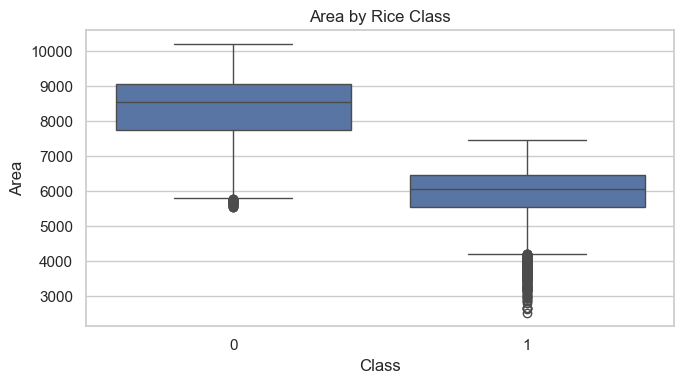

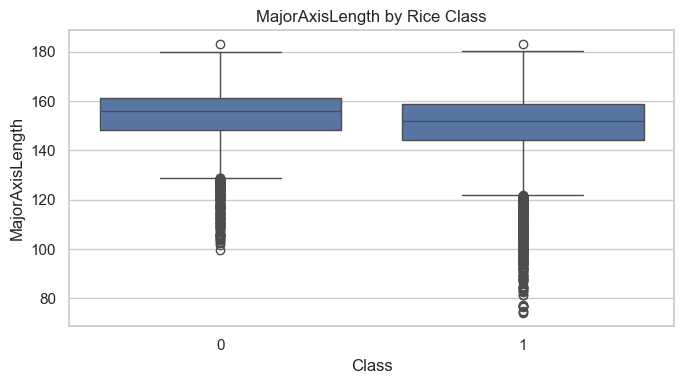

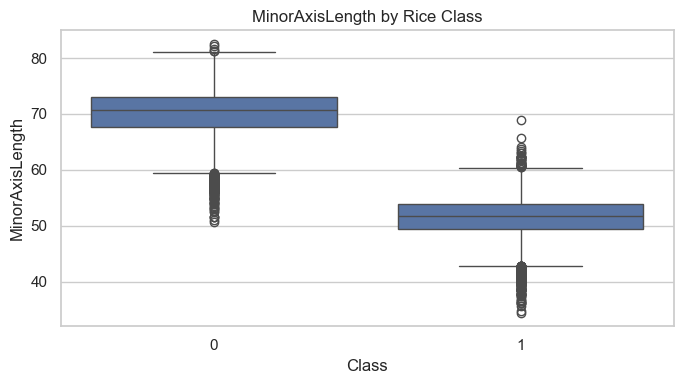

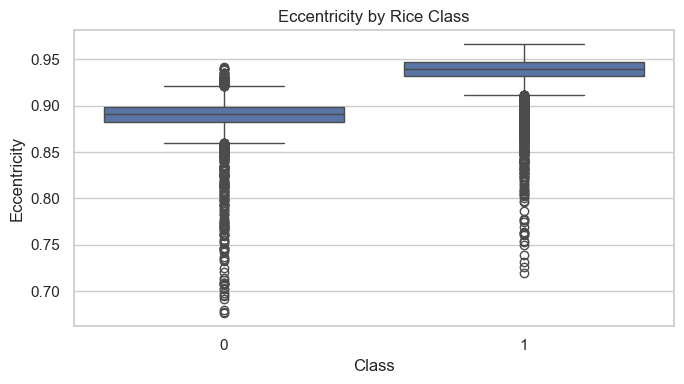

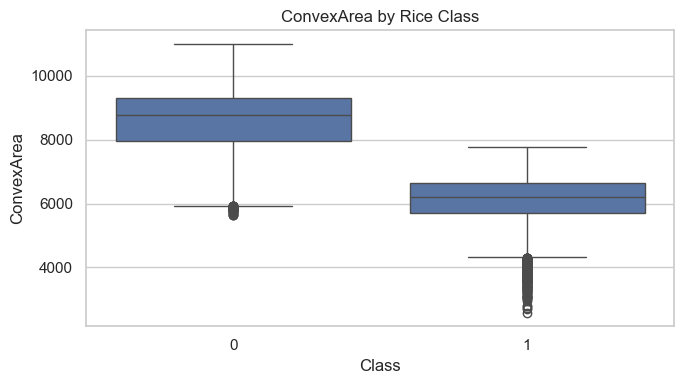

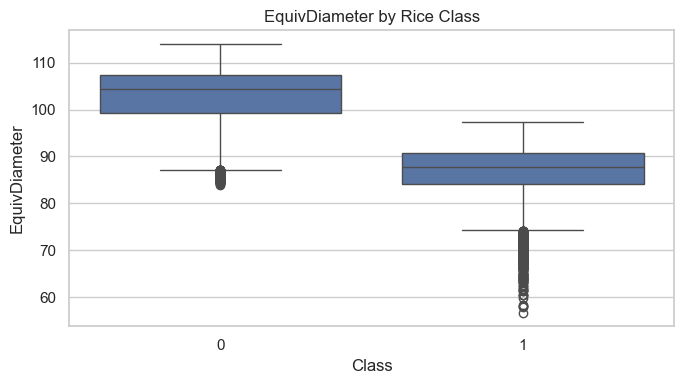

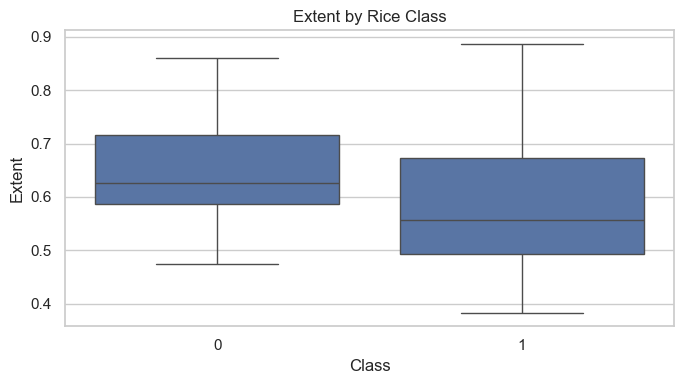

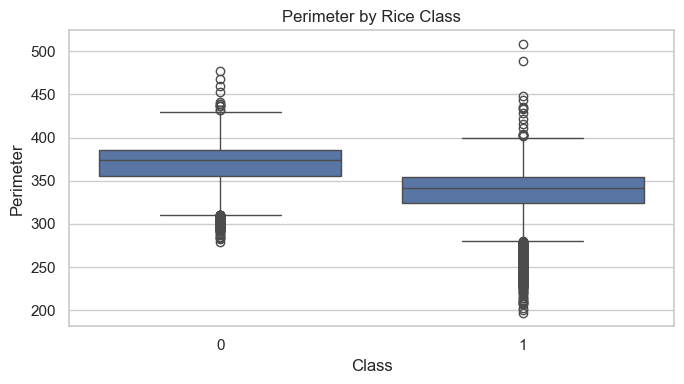

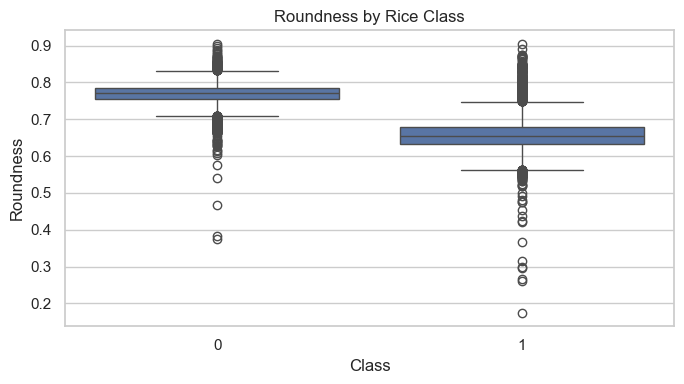

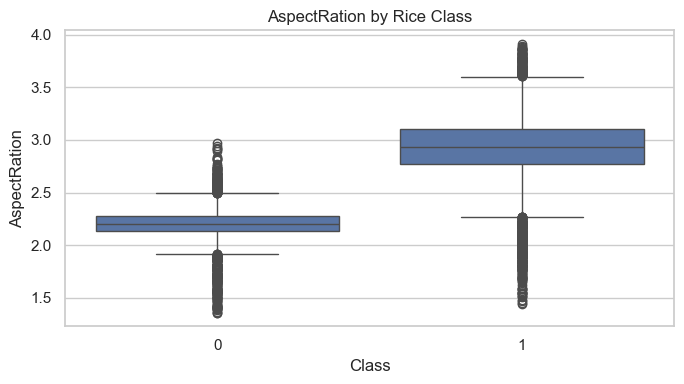

In [22]:
for col in feature_columns:
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=df, x="Class", y=col)
    plt.title(f"{col} by Rice Class")
    plt.tight_layout()
    plt.show()

### 6.5 Correlation heatmap

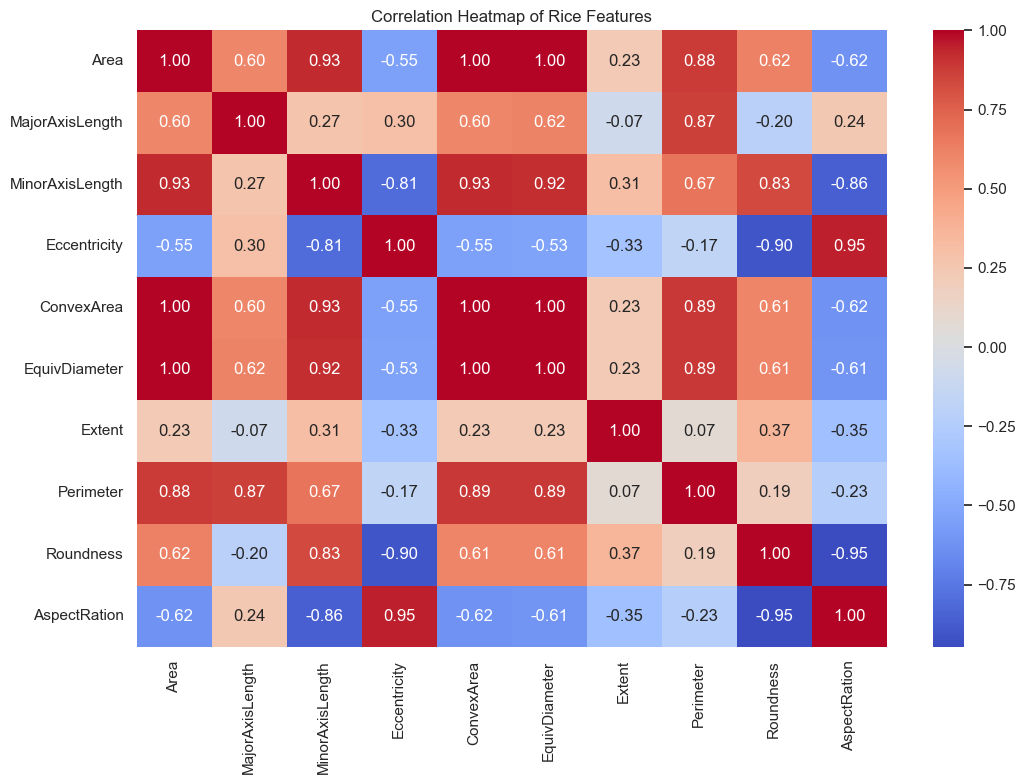

In [24]:
plt.figure(figsize=(11, 8))
sns.heatmap(
    df[feature_columns].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap of Rice Features")
plt.tight_layout()
plt.show()

## 7. Prepare input features and target

In [26]:
# Exclude id because it is only an identifier, not a meaningful predictor.
X = df.drop(columns=["id", "Class"]).copy()
y = df["Class"].astype(int).copy()

print("Input feature shape:", X.shape)
print("Target shape:", y.shape)
print("Input features:", X.columns.tolist())
print("Target classes:", sorted(y.unique().tolist()))

Input feature shape: (18185, 10)
Target shape: (18185,)
Input features: ['Area', 'MajorAxisLength', 'MinorAxisLength', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Perimeter', 'Roundness', 'AspectRation']
Target classes: [0, 1]


## 8. Split data into training and testing sets

In [28]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\\nTraining target distribution:")
display(y_train.value_counts().sort_index().to_frame("Count"))

print("\\nTesting target distribution:")
display(y_test.value_counts().sort_index().to_frame("Count"))

Training samples: 14548
Testing samples: 3637
\nTraining target distribution:


,Count
Class,
0,6560
1,7988


\nTesting target distribution:


,Count
Class,
0,1640
1,1997


## 9. Preprocessing

In [30]:
# All input features in this dataset are numerical.
# Median imputation is included as a safeguard for missing numerical values.
# Standardization is important for Logistic Regression, KNN and SVM.

def make_preprocessor():
    return Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

def make_model_pipeline(classifier):
    return Pipeline(steps=[
        ("preprocessing", make_preprocessor()),
        ("classifier", classifier)
    ])

print("Numerical features:", X.columns.tolist())
print("Preprocessing: median imputation and standardization")

Numerical features: ['Area', 'MajorAxisLength', 'MinorAxisLength', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Perimeter', 'Roundness', 'AspectRation']
Preprocessing: median imputation and standardization


## 10. Define individual base classification models

In [32]:
base_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE
    ),
    "Decision Tree": DecisionTreeClassifier(
        random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=150,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),
    "SVM": SVC(
        kernel="rbf",
        probability=True,
        random_state=RANDOM_STATE
    )
}

print("Five individual base classifiers defined:")
for model_name in base_models:
    print("-", model_name)

Five individual base classifiers defined:
- Logistic Regression
- Decision Tree
- Random Forest
- KNN
- SVM


## 11. Train and evaluate individual base classifiers

In [34]:
trained_models = {}
results = []

def calculate_metrics(model_name, model):
    predictions = model.predict(X_test)

    # Calculate ROC-AUC using predicted probabilities where available.
    if hasattr(model, "predict_proba"):
        probabilities = model.predict_proba(X_test)[:, 1]
        auc = roc_auc_score(y_test, probabilities)
    elif hasattr(model, "decision_function"):
        scores = model.decision_function(X_test)
        auc = roc_auc_score(y_test, scores)
    else:
        auc = np.nan

    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision (Macro)": precision_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Recall (Macro)": recall_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "F1-Score (Macro)": f1_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "ROC-AUC": auc,
        "Balanced Accuracy": balanced_accuracy_score(y_test, predictions)
    }

for name, classifier in base_models.items():
    model = make_model_pipeline(classifier)
    model.fit(X_train, y_train)

    trained_models[name] = model
    results.append(calculate_metrics(name, model))

base_results = pd.DataFrame(results)
display(base_results.round(4))

,Model,Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro),ROC-AUC,Balanced Accuracy
0,Logistic Regression,0.9920,0.9921,0.9918,0.9919,0.9994,0.9918
1,Decision Tree,0.9843,0.9841,0.9843,0.9842,0.9843,0.9843
2,Random Forest,0.9923,0.9924,0.9920,0.9922,0.9989,0.9920
3,KNN,0.9912,0.9911,0.9911,0.9911,0.9966,0.9911
4,SVM,0.9926,0.9928,0.9923,0.9925,0.9981,0.9923


## 12. Implement AdaBoost ensemble

In [36]:
# AdaBoost combines weak learners sequentially.
# A decision stump (Decision Tree with max_depth=1) is the weak learner.
weak_learner = DecisionTreeClassifier(
    max_depth=1,
    random_state=RANDOM_STATE
)

ada_model = Pipeline(steps=[
    ("preprocessing", make_preprocessor()),
    ("classifier", AdaBoostClassifier(
        estimator=weak_learner,
        n_estimators=100,
        learning_rate=0.5,
        random_state=RANDOM_STATE
    ))
])

ada_model.fit(X_train, y_train)

trained_models["AdaBoost"] = ada_model
results.append(calculate_metrics("AdaBoost", ada_model))

print("AdaBoost model trained and evaluated.")
display(pd.DataFrame([results[-1]]).round(4))

AdaBoost model trained and evaluated.


,Model,Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro),ROC-AUC,Balanced Accuracy
0,AdaBoost,0.9909,0.9909,0.9908,0.9908,0.9993,0.9908


## 13. Implement Voting ensemble (majority voting)

In [38]:
# Hard voting selects the class receiving the most votes.
# Each base classifier has its own preprocessing pipeline.
voting_estimators = [
    (name, make_model_pipeline(classifier))
    for name, classifier in base_models.items()
]

voting_classifier = VotingClassifier(
    estimators=voting_estimators,
    voting="hard"
)

voting_model = voting_classifier
voting_model.fit(X_train, y_train)

trained_models["Voting (Majority)"] = voting_model
results.append(calculate_metrics("Voting (Majority)", voting_model))

print("Majority Voting ensemble trained and evaluated.")
display(pd.DataFrame([results[-1]]).round(4))

Majority Voting ensemble trained and evaluated.


,Model,Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro),ROC-AUC,Balanced Accuracy
0,Voting (Majority),0.9926,0.9927,0.9923,0.9925,NaN,0.9923


**Note:** Hard Voting returns majority class labels rather than averaged probabilities. ROC-AUC is therefore not reported for this model; the other classification metrics are still calculated normally.

## 14. Implement Stacking ensemble using a meta-classifier

In [41]:
# Each base estimator includes its own preprocessing pipeline.
# This ensures imputation and scaling are fitted only on the relevant
# training fold during Stacking's internal cross-validation.
stacking_estimators = [
    (name, make_model_pipeline(classifier))
    for name, classifier in base_models.items()
]

# Logistic Regression acts as the meta-classifier.
stacking_model = StackingClassifier(
    estimators=stacking_estimators,
    final_estimator=LogisticRegression(max_iter=2000),
    cv=StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=RANDOM_STATE
    ),
    stack_method="predict_proba",
    n_jobs=-1
)

stacking_model.fit(X_train, y_train)

trained_models["Stacking"] = stacking_model
results.append(calculate_metrics("Stacking", stacking_model))

print("Stacking ensemble trained and evaluated.")
display(pd.DataFrame([results[-1]]).round(4))

Stacking ensemble trained and evaluated.


,Model,Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro),ROC-AUC,Balanced Accuracy
0,Stacking,0.9937,0.9939,0.9934,0.9936,0.9993,0.9934


## 15. Compare base classifiers and ensemble models

In [43]:
comparison_results = pd.DataFrame(results)

comparison_results = comparison_results.sort_values(
    by="F1-Score (Macro)",
    ascending=False
).reset_index(drop=True)

display(comparison_results.round(4))

,Model,Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro),ROC-AUC,Balanced Accuracy
0,Stacking,0.9937,0.9939,0.9934,0.9936,0.9993,0.9934
1,Voting (Majority),0.9926,0.9927,0.9923,0.9925,NaN,0.9923
2,SVM,0.9926,0.9928,0.9923,0.9925,0.9981,0.9923
3,Random Forest,0.9923,0.9924,0.9920,0.9922,0.9989,0.9920
4,Logistic Regression,0.9920,0.9921,0.9918,0.9919,0.9994,0.9918
5,KNN,0.9912,0.9911,0.9911,0.9911,0.9966,0.9911
6,AdaBoost,0.9909,0.9909,0.9908,0.9908,0.9993,0.9908
7,Decision Tree,0.9843,0.9841,0.9843,0.9842,0.9843,0.9843


## 16. Visual comparison of model performance

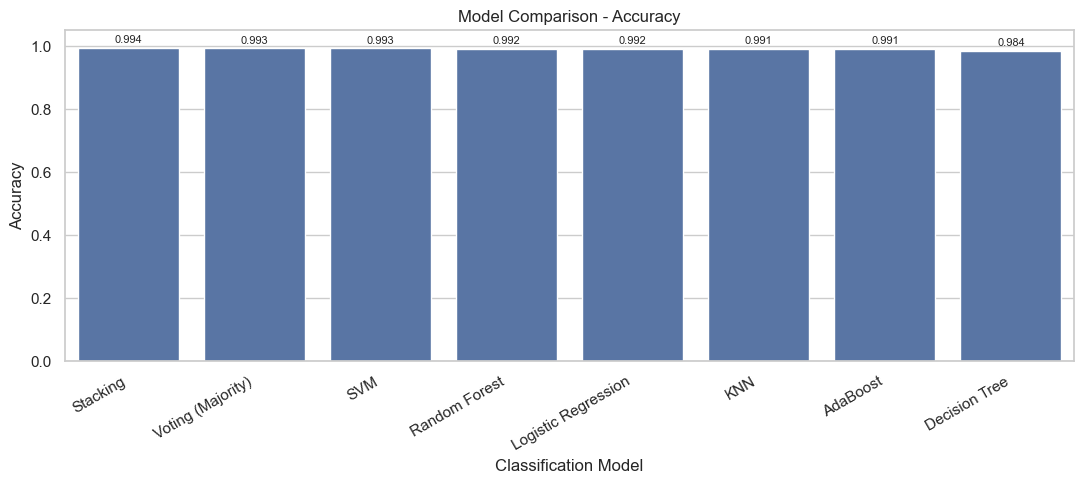

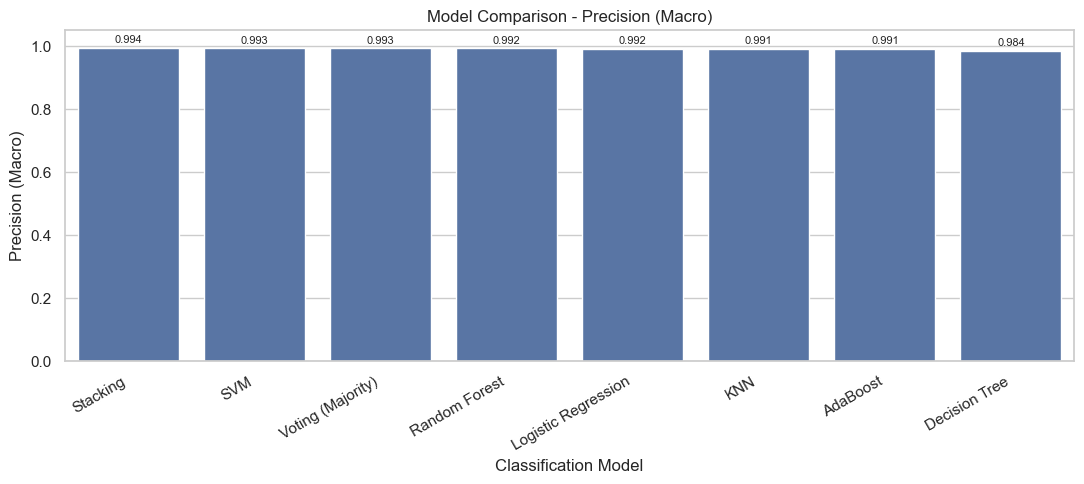

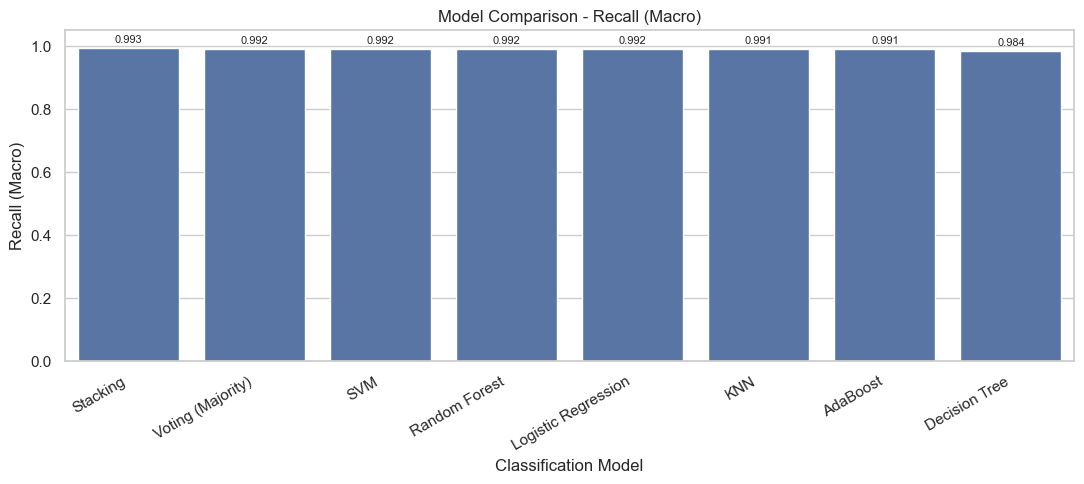

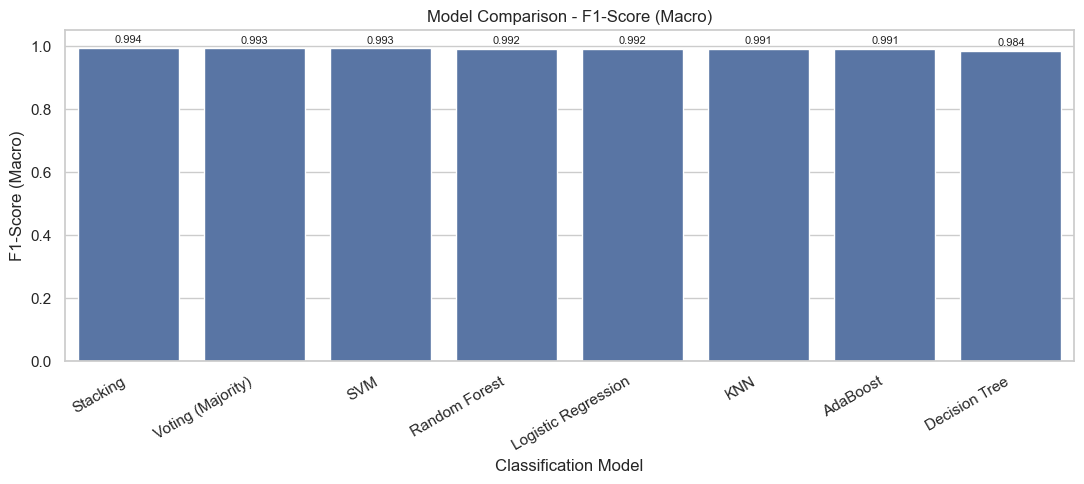

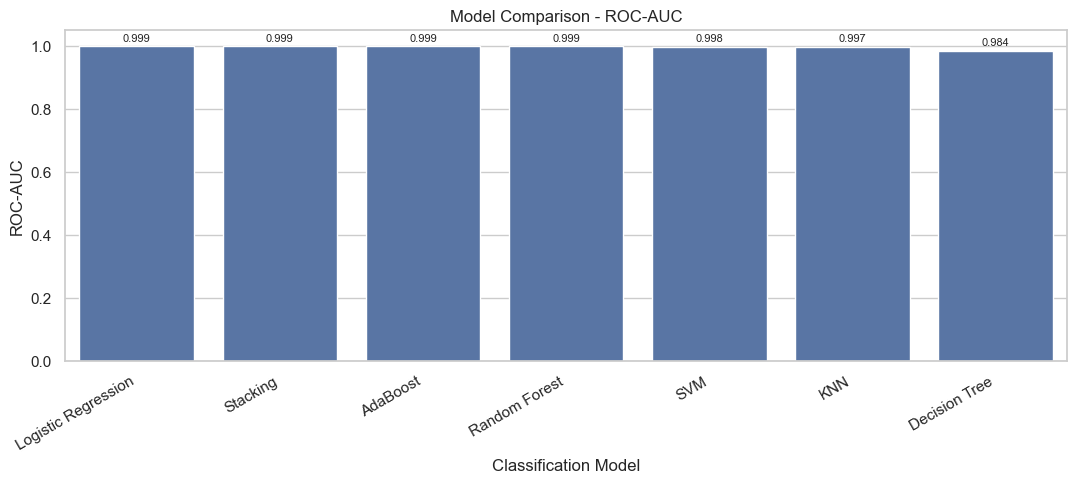

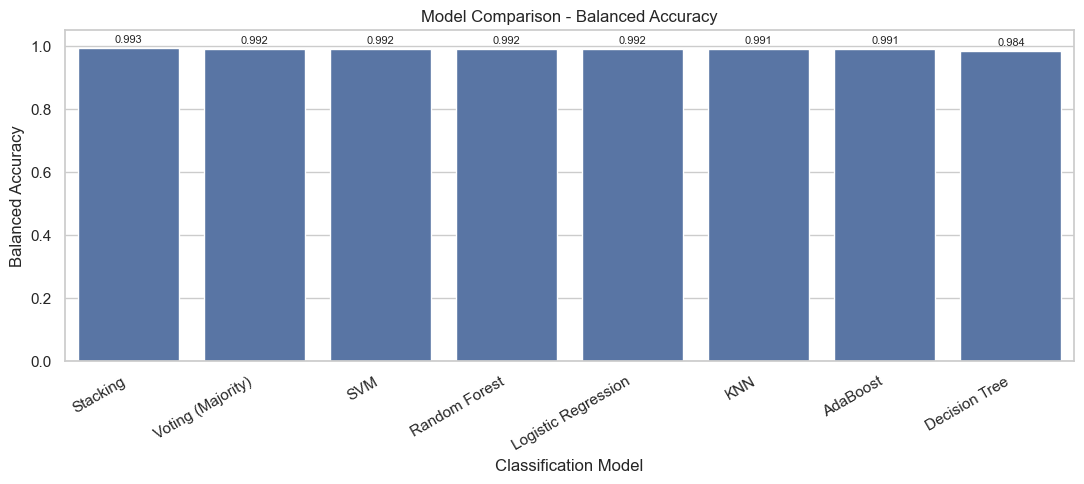

In [45]:
metrics = [
    "Accuracy",
    "Precision (Macro)",
    "Recall (Macro)",
    "F1-Score (Macro)",
    "ROC-AUC",
    "Balanced Accuracy"
]

for metric in metrics:
    plot_data = comparison_results.dropna(subset=[metric]).sort_values(
        metric, ascending=False
    )

    plt.figure(figsize=(11, 5))
    ax = sns.barplot(data=plot_data, x="Model", y=metric)
    plt.title(f"Model Comparison - {metric}")
    plt.xlabel("Classification Model")
    plt.ylabel(metric)
    plt.ylim(0, 1.05)
    plt.xticks(rotation=30, ha="right")

    for container in ax.containers:
        ax.bar_label(container, fmt="%.3f", fontsize=8, padding=2)

    plt.tight_layout()
    plt.show()

## 17. Confusion matrices for all models

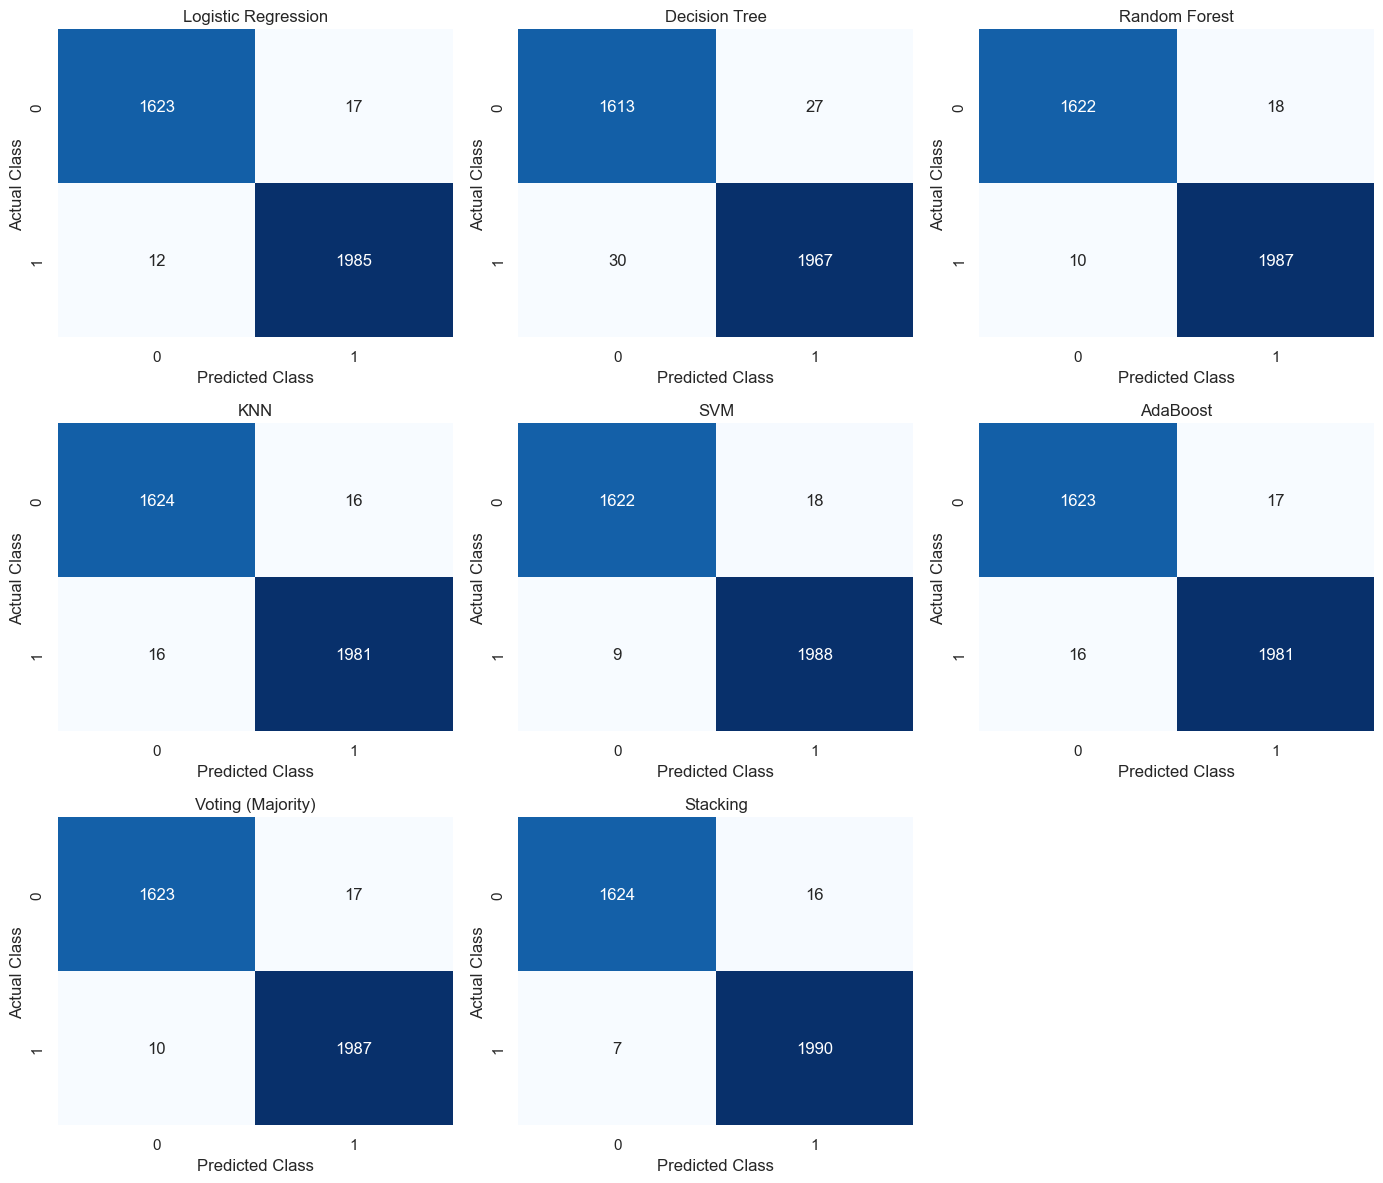

In [47]:
n_models = len(trained_models)
n_cols = 3
n_rows = int(np.ceil(n_models / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 4 * n_rows))
axes = np.array(axes).reshape(-1)

class_labels = [0, 1]

for ax, (name, model) in zip(axes, trained_models.items()):
    predictions = model.predict(X_test)
    cm = confusion_matrix(y_test, predictions, labels=class_labels)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        ax=ax,
        xticklabels=class_labels,
        yticklabels=class_labels
    )
    ax.set_title(name)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

for ax in axes[n_models:]:
    ax.axis("off")

plt.tight_layout()
plt.show()

## 18. Classification reports

In [49]:
for name, model in trained_models.items():
    print("\\n" + "=" * 55)
    print(name)
    print("=" * 55)

    print(classification_report(
        y_test,
        model.predict(X_test),
        labels=[0, 1],
        target_names=["Class 0", "Class 1"],
        zero_division=0
    ))

\n=======================================================
Logistic Regression
              precision    recall  f1-score   support

     Class 0       0.99      0.99      0.99      1640
     Class 1       0.99      0.99      0.99      1997

    accuracy                           0.99      3637
   macro avg       0.99      0.99      0.99      3637
weighted avg       0.99      0.99      0.99      3637

\n=======================================================
Decision Tree
              precision    recall  f1-score   support

     Class 0       0.98      0.98      0.98      1640
     Class 1       0.99      0.98      0.99      1997

    accuracy                           0.98      3637
   macro avg       0.98      0.98      0.98      3637
weighted avg       0.98      0.98      0.98      3637

\n=======================================================
Random Forest
              precision    recall  f1-score   support

     Class 0       0.99      0.99      0.99      1640
     Class 1   